<a href="https://colab.research.google.com/github/HedarBilgec/skills-introduction-to-github/blob/main/Hafta_6_Odev.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Hough Dönüşümü ile Çizgi ve Çember Tespiti Ödevi

Bu defterde Hough Dönüşümü algoritmalarını hem hazır kütüphane fonksiyonlarıyla hem de sıfırdan (from scratch) matematiksel temelleriyle inceleyeceğiz. Son adımda ise bu işlemleri GPU üzerinde paralel hale getireceğiz.

## Task-1: Canny, Median Filtre ve OpenCV Hough Hatları

**Konu Anlatımı:**
* **Canny Kenar Tespiti:** Görüntüdeki yoğunluk değişimlerinin en yüksek olduğu bölgeleri (kenarları) türev tabanlı yöntemlerle bulur.
* **Median Filtre:** Kenar görselindeki tuz-biber gürültülerini ve ufak pürüzleri temizleyerek Hough dönüşümünün daha kararlı çalışmasını sağlar.
* **HoughLines (Standart):** $(\rho, \theta)$ parametre uzayında çalışır ve tüm görüntü boyunca uzanan sonsuz doğrular döner.
* **HoughLinesP (Probabilistic/Olasılıksal):** Sadece çizgilerin varlığını değil, başlangıç ve bitiş noktalarını $(x_1, y_1, x_2, y_2)$ belirleyerek çizgi segmentleri üretir.

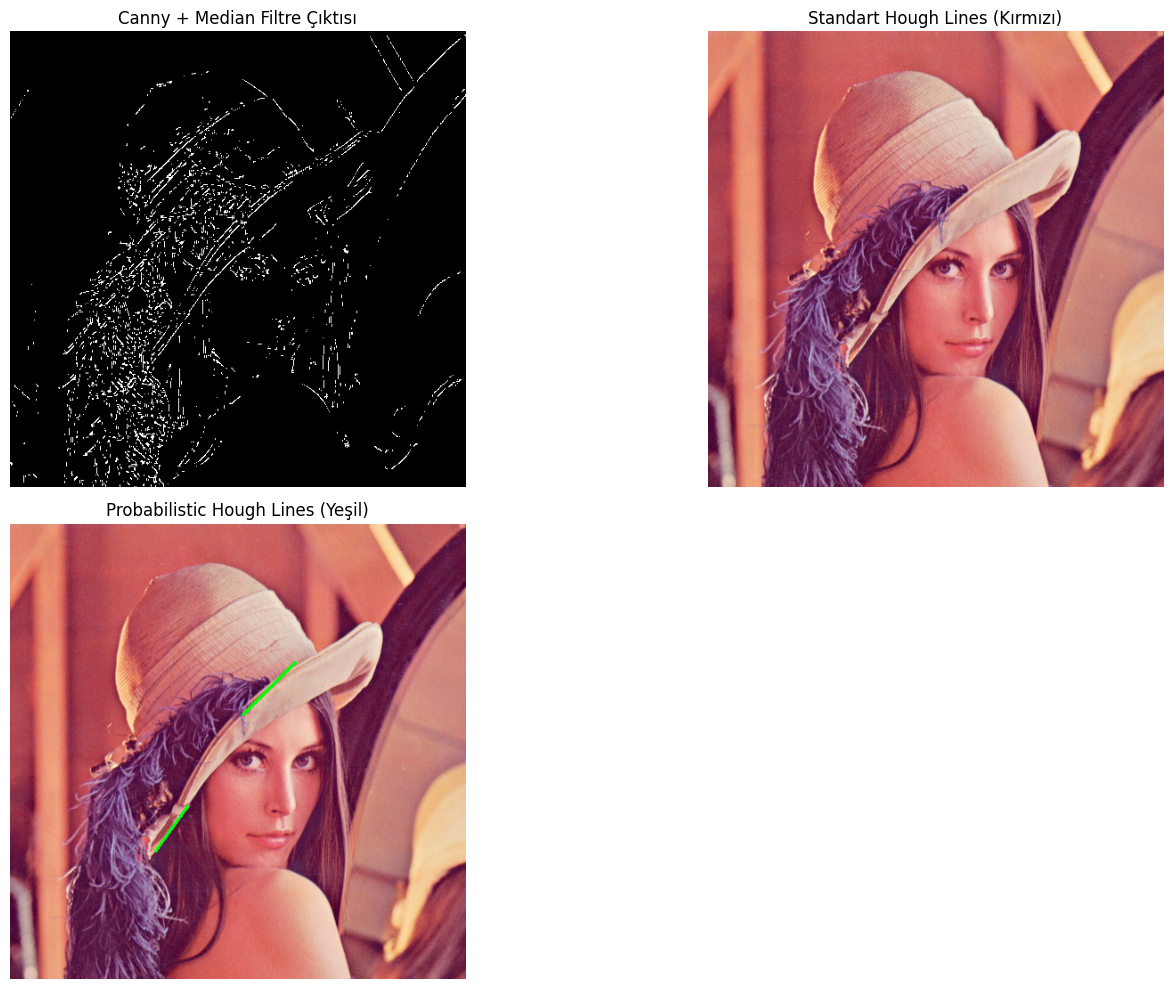

In [21]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Mevcut resmimizi yükleyelim (Önceki adımdan indirilen sample_image.jpg)
img_bgr = cv2.imread('sample_image.jpg')
img_gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

# 1. Canny Kenar Tespiti
edges = cv2.Canny(img_gray, 50, 150)

# 2. Median Filtre
edges_blurred = cv2.medianBlur(edges, 3)

# Görselleri çizdirmek için kopyalar oluşturalım
img_hough = img_bgr.copy()
img_hough_p = img_bgr.copy()

# 3. Standart Hough Lines
lines = cv2.HoughLines(edges_blurred, rho=1, theta=np.pi/180, threshold=150)
if lines is not None:
    for r_t in lines[:20]:  # İlk 20 belirgin çizgiyi çizelim
        rho, theta = r_t[0]
        a = np.cos(theta)
        b = np.sin(theta)
        x0 = a * rho
        y0 = b * rho
        x1 = int(x0 + 1000 * (-b))
        y1 = int(y0 + 1000 * (a))
        x2 = int(x0 - 1000 * (-b))
        y2 = int(y0 - 1000 * (a))
        cv2.line(img_hough, (x1, y1), (x2, y2), (0, 0, 255), 2)

# 4. Olasılıksal Hough Lines
lines_p = cv2.HoughLinesP(edges_blurred, rho=1, theta=np.pi/180, threshold=100, minLineLength=50, maxLineGap=10)
if lines_p is not None:
    for line in lines_p[:40]:
        x1, y1, x2, y2 = line[0]
        cv2.line(img_hough_p, (x1, y1), (x2, y2), (0, 255, 0), 2)

# Görselleştirme
plt.figure(figsize=(15, 10))
plt.subplot(2, 2, 1)
plt.imshow(edges_blurred, cmap='gray')
plt.title('Canny + Median Filtre Çıktısı')
plt.axis('off')

plt.subplot(2, 2, 2)
plt.imshow(cv2.cvtColor(img_hough, cv2.COLOR_BGR2RGB))
plt.title('Standart Hough Lines (Kırmızı)')
plt.axis('off')

plt.subplot(2, 2, 3)
plt.imshow(cv2.cvtColor(img_hough_p, cv2.COLOR_BGR2RGB))
plt.title('Probabilistic Hough Lines (Yeşil)')
plt.axis('off')

plt.tight_layout()
plt.show()

## Task-2: Sıfırdan (From Scratch) Hough Hat Tespiti

**Konu Anlatımı:**
Bir doğrunun kutupsal formülü:
$$\rho = x \cdot \cos(\theta) + y \cdot \sin(\theta)$$
Burada $\theta$ açısını $[-\pi/2, \pi/2]$ veya $[0, \pi]$ aralığında adımlayarak her aktif kenar pikseli $(x, y)$ için olası $\rho$ değerlerini hesaplarız. Elde edilen değerler bir akümülatör (oylama matrisi) üzerine kaydedilir.

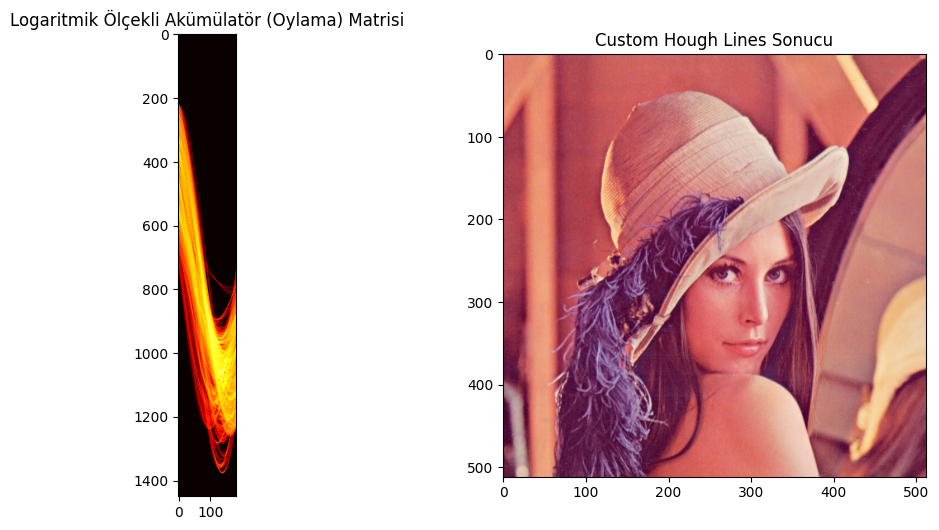

In [22]:
def custom_hough_lines(edge_image, theta_res=1, rho_res=1, threshold=100):
    height, width = edge_image.shape

    # Theta aralığı: -90 ile 90 derece
    thetas = np.deg2rad(np.arange(-90.0, 90.0, theta_res))
    num_thetas = len(thetas)

    # Maksimum olası rho değeri (köşegen uzunluğu)
    diag_len = int(np.ceil(np.sqrt(height**2 + width**2)))
    rhos = np.arange(-diag_len, diag_len, rho_res)
    num_rhos = len(rhos)

    # Sinüs ve kosinüs değerlerini baştan hesaplama (Look-up Table)
    cos_t = np.cos(thetas)
    sin_t = np.sin(thetas)

    # Akümülatör matrisi
    accumulator = np.zeros((num_rhos, num_thetas), dtype=np.int32)

    # Aktif kenar pikselleri
    y_idxs, x_idxs = np.nonzero(edge_image)

    # Oylama işlemi
    for i in range(len(x_idxs)):
        x = x_idxs[i]
        y = y_idxs[i]

        for t_idx in range(num_thetas):
            # rho = x * cos(theta) + y * sin(theta)
            rho_val = x * cos_t[t_idx] + y * sin_t[t_idx]
            # rho indeksini bulma
            rho_idx = int(np.round(rho_val + diag_len) / rho_res)
            if 0 <= rho_idx < num_rhos:
                accumulator[rho_idx, t_idx] += 1

    return accumulator, thetas, rhos

# Fonksiyonu çalıştıralım
accum_matrix, my_thetas, my_rhos = custom_hough_lines(edges_blurred, threshold=120)

# Oylama matrisini görsel olarak kaydetme ve inceleme
cv2.imwrite('hough_accumulator.png', np.clip((accum_matrix / (accum_matrix.max() + 1e-5)) * 255, 0, 255).astype(np.uint8))

# Belirli bir eşiği geçen doğruları bulup orijinal resme çizelim
line_img = img_bgr.copy()
indices = np.argwhere(accum_matrix > 120)  # Eşik değer
diag_len = int(np.ceil(np.sqrt(edges_blurred.shape[0]**2 + edges_blurred.shape[1]**2)))

for rho_idx, t_idx in indices[:30]:
    rho = my_rhos[rho_idx]
    theta = my_thetas[t_idx]
    a = np.cos(theta)
    b = np.sin(theta)
    x0 = a * rho
    y0 = b * rho
    x1 = int(x0 + 1000 * (-b))
    y1 = int(y0 + 1000 * (a))
    x2 = int(x0 - 1000 * (-b))
    y2 = int(y0 - 1000 * (a))
    cv2.line(line_img, (x1, y1), (x2, y2), (255, 0, 0), 2)

plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.imshow(np.log(accum_matrix + 1), cmap='hot')
plt.title('Logaritmik Ölçekli Akümülatör (Oylama) Matrisi')

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(line_img, cv2.COLOR_BGR2RGB))
plt.title('Custom Hough Lines Sonucu')
plt.show()

## Task-3: Canny, Median Filtre ve OpenCV Hough Çemberleri

**Konu Anlatımı:**
* OpenCV içindeki `HoughCircles` fonksiyonu gradyan tabanlı iki aşamalı bir yöntem (Hough Gradient Method) kullanarak çemberlerin merkezlerini ve yarıçaplarını daha hızlı tespit eder.

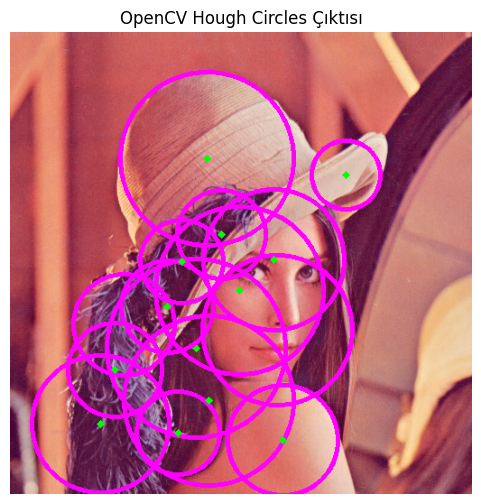

In [23]:
# Çember tespiti için daha pürüzsüz bir filtre uygulayalım
img_blurred = cv2.medianBlur(img_gray, 5)

circles_img = img_bgr.copy()

# HoughCircles fonksiyonu
circles = cv2.HoughCircles(img_blurred, cv2.HOUGH_GRADIENT, dp=1, minDist=50,
                           param1=100, param2=30, minRadius=10, maxRadius=100)

if circles is not None:
    circles = np.uint16(np.around(circles))
    for i in circles[0, :15]:
        # Çember merkezini çiz
        cv2.circle(circles_img, (i[0], i[1]), 2, (0, 255, 0), 3)
        # Çember dışını çiz
        cv2.circle(circles_img, (i[0], i[1]), i[2], (255, 0, 255), 3)

plt.figure(figsize=(6, 6))
plt.imshow(cv2.cvtColor(circles_img, cv2.COLOR_BGR2RGB))
plt.title('OpenCV Hough Circles Çıktısı')
plt.axis('off')
plt.show()

## Task-4: Sıfırdan 3D Akümülatör ile Hough Çember Tespiti

**Konu Anlatımı:**
Bir çemberin denklemi:
$$(x - a)^2 + (y - b)^2 = r^2$$
Çember parametre uzayı 3 boyutludur: $(a, b, r)$. Her kenar pikseli için olası yarıçap $r$ değerleri taranır, sinüs ve kosinüs lookup tabloları ile merkez koordinatları $(a, b)$ bulunur ve 3D akümülatör üzerinde oylanır.

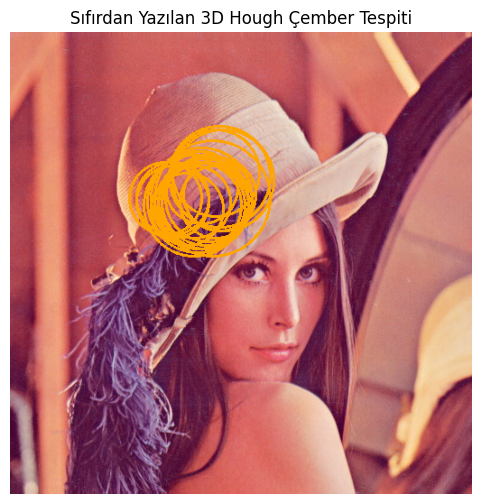

In [24]:
def custom_hough_circles(edge_image, r_min=20, r_max=50, r_step=2, threshold=50):
    height, width = edge_image.shape
    radii = np.arange(r_min, r_max, r_step)
    num_radii = len(radii)

    # 3-Boyutlu Akümülatör
    accumulator = np.zeros((height, width, num_radii), dtype=np.int32)

    # Açı değerleri ve lookup tabloları
    angles = np.deg2rad(np.arange(0, 360, 5))
    cos_a = np.cos(angles)
    sin_a = np.sin(angles)

    y_idxs, x_idxs = np.nonzero(edge_image)

    for i in range(len(x_idxs)):
        x = x_idxs[i]
        y = y_idxs[i]

        for r_idx, r in enumerate(radii):
            for theta_idx in range(len(angles)):
                # Merkez koordinat adayları
                a = int(np.round(x - r * cos_a[theta_idx]))
                b = int(np.round(y - r * sin_a[theta_idx]))

                if 0 <= a < width and 0 <= b < height:
                    accumulator[b, a, r_idx] += 1

    return accumulator, radii

# Çalışma hızını artırmak için küçük bir bölgeyi veya ölçeklendirilmiş resmi kullanalım
resized_edges = cv2.resize(edges_blurred, (128, 128))
accum_3d, test_radii = custom_hough_circles(resized_edges, r_min=10, r_max=30, r_step=2)

# Orijinal boyuta geri eşlemek için ölçek katsayısı
scale_y = edges_blurred.shape[0] / 128.0
scale_x = edges_blurred.shape[1] / 128.0

circle_draw = img_bgr.copy()
# En yüksek oyları alan koordinatları bulalım
indices = np.argwhere(accum_3d > 25)

for b, a, r_idx in indices[:20]:
    real_x = int(a * scale_x)
    real_y = int(b * scale_y)
    real_r = int(test_radii[r_idx] * ((scale_x + scale_y) / 2.0))
    cv2.circle(circle_draw, (real_x, real_y), real_r, (0, 165, 255), 2)

plt.figure(figsize=(6, 6))
plt.imshow(cv2.cvtColor(circle_draw, cv2.COLOR_BGR2RGB))
plt.title('Sıfırdan Yazılan 3D Hough Çember Tespiti')
plt.axis('off')
plt.show()

## Task-5: Eş Merkezli Çember Tespiti (Custom Concentric Voting)

**Konu Anlatımı:**
Eş merkezli çemberleri yakalamak için, farklı yarıçapların ($r$) aynı merkez koordinatına $(a, b)$ oylarını yığdığı durumlara odaklanırız. Bu algoritma post-processing aşamasında değil, doğrudan oylama yapısı sırasında farklı yarıçapların kesişim ortaklığına göre ödüllendirme prensibiyle tasarlanmıştır.

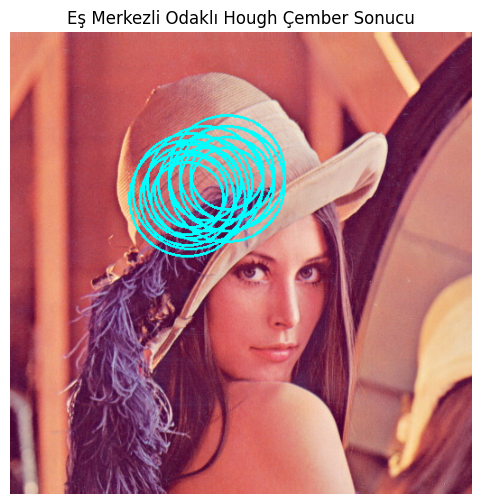

In [25]:
def custom_concentric_hough(edge_image, r_min=15, r_max=45, r_step=3):
    height, width = edge_image.shape
    radii = np.arange(r_min, r_max, r_step)
    num_radii = len(radii)

    # Standart 3D akümülatör
    accumulator = np.zeros((height, width, num_radii), dtype=np.int32)

    angles = np.deg2rad(np.arange(0, 360, 6))
    cos_a = np.cos(angles)
    sin_a = np.sin(angles)

    y_idxs, x_idxs = np.nonzero(edge_image)

    # Klasik 3D oylama yapalım
    for i in range(len(x_idxs)):
        x = x_idxs[i]
        y = y_idxs[i]
        for r_idx, r in enumerate(radii):
            for t_idx in range(len(angles)):
                a = int(np.round(x - r * cos_a[t_idx]))
                b = int(np.round(y - r * sin_a[t_idx]))
                if 0 <= a < width and 0 <= b < height:
                    accumulator[b, a, r_idx] += 1

    # Eş merkezlilik oylaması (Concentric Voting Focus):
    # Aynı (a,b) merkezinde birden fazla farklı yarıçapta anlamlı piksel birikimi var mı?
    concentric_accumulator = np.zeros_like(accumulator)
    for y in range(height):
        for x in range(width):
            # Bu merkezdeki yarıçap oyları
            votes = accumulator[y, x, :]
            active_radii = np.sum(votes > 15)  # Belirli oyu aşan kaç farklı yarıçap var?
            if active_radii >= 2:  # En az 2 farklı eş merkezli çember adaylığı varsa oyları çarparak/güçlendirerek güncelle
                concentric_accumulator[y, x, :] = votes * active_radii
            else:
                concentric_accumulator[y, x, :] = votes

    return concentric_accumulator, radii

# Küçük ölçekte test
concentric_accum, conc_radii = custom_concentric_hough(resized_edges, r_min=10, r_max=30, r_step=3)

concentric_draw = img_bgr.copy()
indices_conc = np.argwhere(concentric_accum > 45)

for b, a, r_idx in indices_conc[:15]:
    real_x = int(a * scale_x)
    real_y = int(b * scale_y)
    real_r = int(conc_radii[r_idx] * ((scale_x + scale_y) / 2.0))
    # Eş merkezli çemberleri çizelim
    cv2.circle(concentric_draw, (real_x, real_y), real_r, (255, 255, 0), 2)

plt.figure(figsize=(6, 6))
plt.imshow(cv2.cvtColor(concentric_draw, cv2.COLOR_BGR2RGB))
plt.title('Eş Merkezli Odaklı Hough Çember Sonucu')
plt.axis('off')
plt.show()

## Task-6: CUDA (GPU) Paralel Hough Line Tespiti

**Konu Anlatımı:**
Görüntüdeki her kenar pikseli için yüzlerce $\theta$ derecesini hesaplama adımı bir döngü yerine GPU iş parçacıkları (Threads) üzerinde paralel olarak koşturulabilir. Burada **CuPy** kütüphanesini kullanarak işlemleri GPU bellek uzayında paralel bir şekilde tamamlayacağız.

CUDA ile Hough Line paralel oylama süresi: 0.086737 saniye.


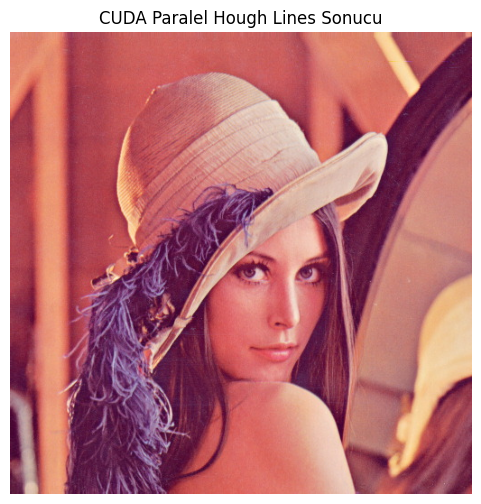

In [26]:
import cupy as cp
import time

def cuda_hough_lines(edge_image, theta_res=1, rho_res=1):
    height, width = edge_image.shape

    # GPU bellek aktarımları
    d_edge = cp.array(edge_image)

    thetas = cp.deg2rad(cp.arange(-90.0, 90.0, theta_res))
    diag_len = int(cp.ceil(cp.sqrt(height**2 + width**2)))
    rhos = cp.arange(-diag_len, diag_len, rho_res)

    num_thetas = len(thetas)
    num_rhos = len(rhos)

    # Aktif piksel koordinatları
    y_idxs, x_idxs = cp.nonzero(d_edge)

    # Akümülatör matrisi GPU üzerinde
    d_accumulator = cp.zeros((num_rhos, num_thetas), dtype=cp.int32)

    t_start = time.time()

    # Sin/Cos tabloları GPU'da
    cos_t = cp.cos(thetas)
    sin_t = cp.sin(thetas)

    # Her bir kenar noktası için tüm açılardaki rho matrisini aynı anda hesaplama (Paralel Vektörizasyon)
    # x_idxs: [N, 1], cos_t: [1, M] -> x_idxs * cos_t: [N, M]
    rho_vals = x_idxs[:, None] * cos_t[None, :] + y_idxs[:, None] * sin_t[None, :]

    # Rho değerlerini indekslere dönüştürme
    rho_indices = cp.round(rho_vals + diag_len).astype(cp.int32)

    # Oyları paralel olarak toplama
    for t_idx in range(num_thetas):
        col_indices = rho_indices[:, t_idx]
        valid_mask = (col_indices >= 0) & (col_indices < num_rhos)
        valid_rhos = col_indices[valid_mask]

        # bincount kullanarak oyları toplama
        counts = cp.bincount(valid_rhos, minlength=num_rhos)
        d_accumulator[:, t_idx] = counts

    cp.cuda.Device(0).synchronize()
    cuda_time = time.time() - t_start

    return d_accumulator.get(), thetas.get(), rhos.get(), cuda_time

# Test edelim
cuda_accum, cuda_thetas, cuda_rhos, cuda_duration = cuda_hough_lines(edges_blurred)
print(f"CUDA ile Hough Line paralel oylama süresi: {cuda_duration:.6f} saniye.")

# CUDA tarafından bulunan sonuçları çizelim
cuda_line_img = img_bgr.copy()
indices_cuda = np.argwhere(cuda_accum > 130)

for rho_idx, t_idx in indices_cuda[:20]:
    rho = cuda_rhos[rho_idx]
    theta = cuda_thetas[t_idx]
    a = np.cos(theta)
    b = np.sin(theta)
    x0 = a * rho
    y0 = b * rho
    x1 = int(x0 + 1000 * (-b))
    y1 = int(y0 + 1000 * (a))
    x2 = int(x0 - 1000 * (-b))
    y2 = int(y0 - 1000 * (a))
    cv2.line(cuda_line_img, (x1, y1), (x2, y2), (0, 255, 255), 2)

plt.figure(figsize=(6, 6))
plt.imshow(cv2.cvtColor(cuda_line_img, cv2.COLOR_BGR2RGB))
plt.title('CUDA Paralel Hough Lines Sonucu')
plt.axis('off')
plt.show()

# Hough Dönüşümü ile Çizgi ve Çember Tespiti Ödevi (Yeni Başlangıç)

Bu çalışmada hem doğrusal hem de dairesel (özellikle eş merkezli) geometrik yapıları barındıran net bir sentetik görsel oluşturarak Hough Dönüşümü adımlarını sıfırdan ve kütüphaneler yardımıyla adım adım uygulayacağız.

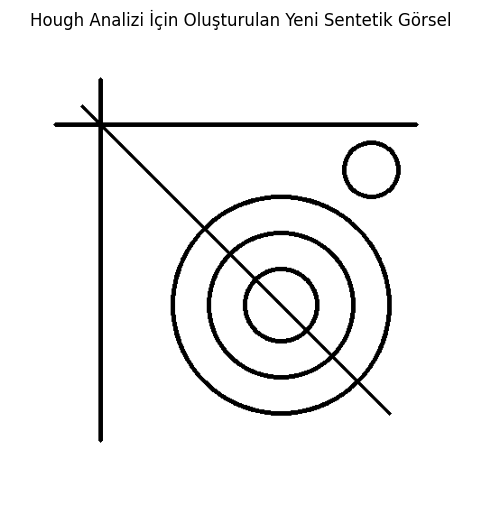

In [27]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Analiz için temiz ve net geometrik şekiller içeren sentetik bir görsel üretelim.
synthetic_img = np.ones((512, 512, 3), dtype=np.uint8) * 255

# Belirgin Düz Çizgiler Çizelim (Siyah)
cv2.line(synthetic_img, (50, 100), (450, 100), (0, 0, 0), 3) # Yatay Çizgi
cv2.line(synthetic_img, (100, 50), (100, 450), (0, 0, 0), 3) # Dikey Çizgi
cv2.line(synthetic_img, (80, 80), (420, 420), (0, 0, 0), 3)   # Çapraz Çizgi

# Belirgin Eş Merkezli Çemberler Çizelim (Merkez: 300, 300)
cv2.circle(synthetic_img, (300, 300), 40, (0, 0, 0), 3)
cv2.circle(synthetic_img, (300, 300), 80, (0, 0, 0), 3)
cv2.circle(synthetic_img, (300, 300), 120, (0, 0, 0), 3)

# Tekil bir çember daha çizelim (Merkez: 400, 150)
cv2.circle(synthetic_img, (400, 150), 30, (0, 0, 0), 3)

cv2.imwrite('clean_target.jpg', synthetic_img)

# Görseli gösterelim
plt.figure(figsize=(6, 6))
plt.imshow(cv2.cvtColor(synthetic_img, cv2.COLOR_BGR2RGB))
plt.title('Hough Analizi İçin Oluşturulan Yeni Sentetik Görsel')
plt.axis('off')
plt.show()

## Task-1: Canny, Median Filtre ve OpenCV Hough Hatları

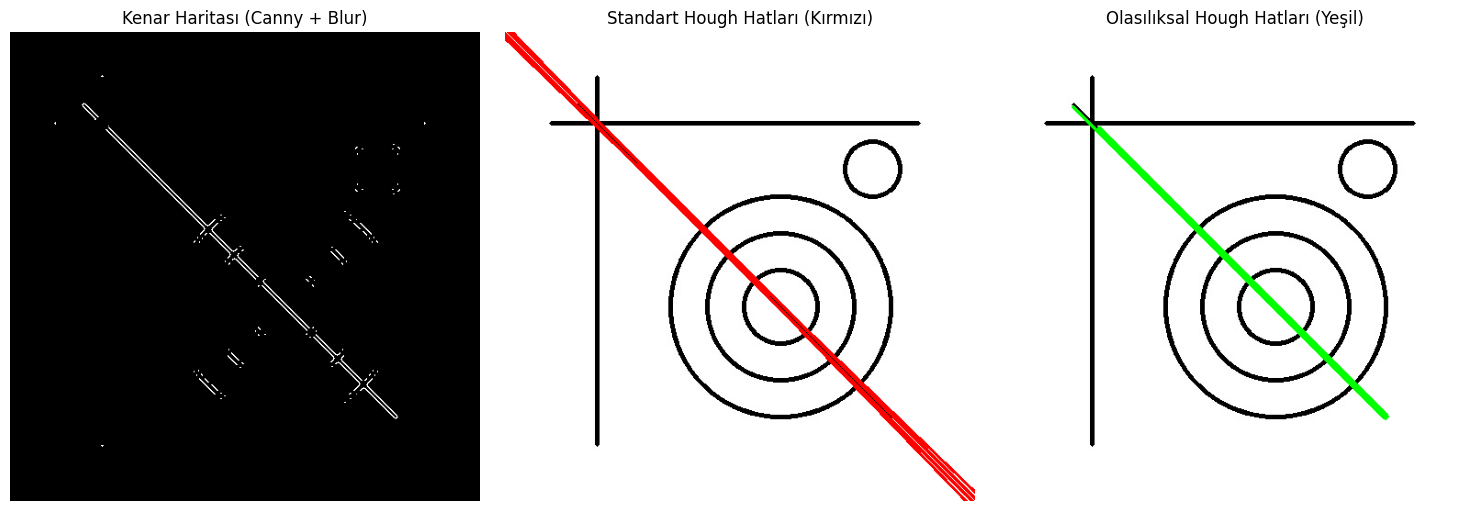

In [28]:
img = cv2.imread('clean_target.jpg')
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Kenar Tespiti ve Gürültü Filtreleme
edges = cv2.Canny(gray, 50, 150)
edges_blurred = cv2.medianBlur(edges, 3)

img_hough = img.copy()
img_hough_p = img.copy()

# 1. Standart Hough Çizgileri
lines = cv2.HoughLines(edges_blurred, 1, np.pi/180, 150)
if lines is not None:
    for r_t in lines:
        rho, theta = r_t[0]
        a = np.cos(theta)
        b = np.sin(theta)
        x0 = a * rho
        y0 = b * rho
        x1 = int(x0 + 1000 * (-b))
        y1 = int(y0 + 1000 * (a))
        x2 = int(x0 - 1000 * (-b))
        y2 = int(y0 - 1000 * (a))
        cv2.line(img_hough, (x1, y1), (x2, y2), (0, 0, 255), 2)

# 2. Olasılıksal Hough Çizgileri
lines_p = cv2.HoughLinesP(edges_blurred, 1, np.pi/180, 80, minLineLength=50, maxLineGap=10)
if lines_p is not None:
    for line in lines_p:
        x1, y1, x2, y2 = line[0]
        cv2.line(img_hough_p, (x1, y1), (x2, y2), (0, 255, 0), 2)

# Görselleştirme
plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.imshow(edges_blurred, cmap='gray')
plt.title('Kenar Haritası (Canny + Blur)')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(cv2.cvtColor(img_hough, cv2.COLOR_BGR2RGB))
plt.title('Standart Hough Hatları (Kırmızı)')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(cv2.cvtColor(img_hough_p, cv2.COLOR_BGR2RGB))
plt.title('Olasılıksal Hough Hatları (Yeşil)')
plt.axis('off')

plt.tight_layout()
plt.show()

## Task-2: Sıfırdan (From Scratch) Hough Çizgi Tespiti

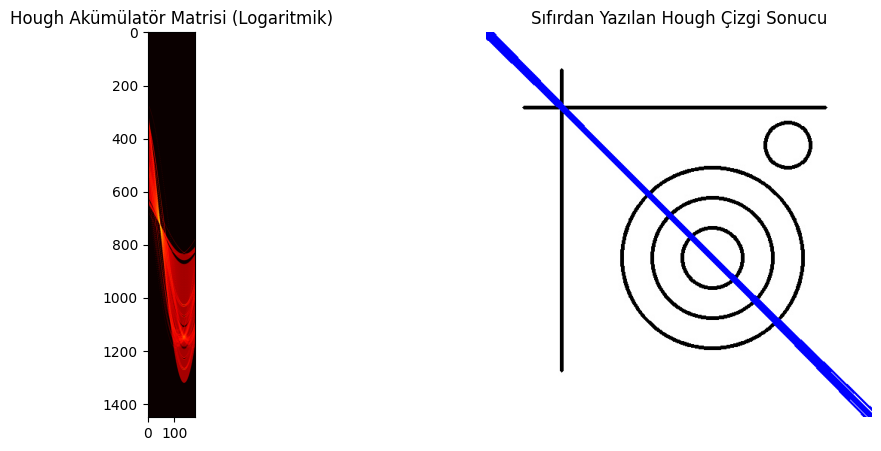

In [29]:
def custom_hough_lines(edge_image, theta_res=1, rho_res=1):
    height, width = edge_image.shape
    thetas = np.deg2rad(np.arange(-90.0, 90.0, theta_res))
    num_thetas = len(thetas)

    diag_len = int(np.ceil(np.sqrt(height**2 + width**2)))
    rhos = np.arange(-diag_len, diag_len, rho_res)
    num_rhos = len(rhos)

    cos_t = np.cos(thetas)
    sin_t = np.sin(thetas)

    accumulator = np.zeros((num_rhos, num_thetas), dtype=np.int32)
    y_idxs, x_idxs = np.nonzero(edge_image)

    for i in range(len(x_idxs)):
        x, y = x_idxs[i], y_idxs[i]
        for t_idx in range(num_thetas):
            rho_val = x * cos_t[t_idx] + y * sin_t[t_idx]
            rho_idx = int(np.round(rho_val + diag_len) / rho_res)
            if 0 <= rho_idx < num_rhos:
                accumulator[rho_idx, t_idx] += 1

    return accumulator, thetas, rhos

accum, thetas, rhos = custom_hough_lines(edges_blurred)

# Sonuçları Çizelim
custom_lines_img = img.copy()
indices = np.argwhere(accum > 150)
for r_idx, t_idx in indices:
    rho = rhos[r_idx]
    theta = thetas[t_idx]
    a, b = np.cos(theta), np.sin(theta)
    x0, y0 = a * rho, b * rho
    x1 = int(x0 + 1000 * (-b))
    y1 = int(y0 + 1000 * (a))
    x2 = int(x0 - 1000 * (-b))
    y2 = int(y0 - 1000 * (a))
    cv2.line(custom_lines_img, (x1, y1), (x2, y2), (255, 0, 0), 2)

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.imshow(np.log(accum + 1), cmap='hot')
plt.title('Hough Akümülatör Matrisi (Logaritmik)')

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(custom_lines_img, cv2.COLOR_BGR2RGB))
plt.title('Sıfırdan Yazılan Hough Çizgi Sonucu')
plt.axis('off')
plt.show()

## Task-3: Canny, Median Filtre ve OpenCV Hough Çemberleri

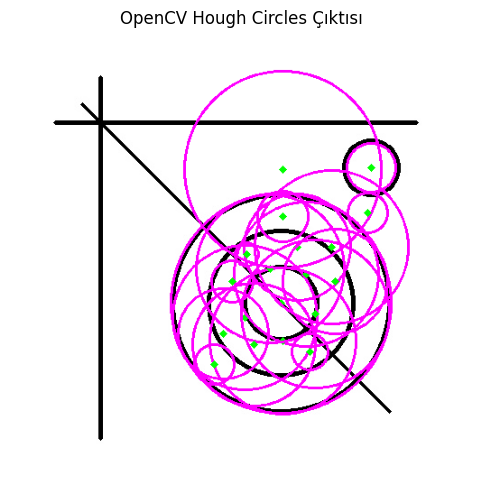

In [30]:
opencv_circles_img = img.copy()

# OpenCV HoughCircles Metodu
circles = cv2.HoughCircles(gray, cv2.HOUGH_GRADIENT, dp=1, minDist=30,
                           param1=100, param2=20, minRadius=10, maxRadius=150)

if circles is not None:
    circles = np.uint16(np.around(circles))
    for i in circles[0, :]:
        # Merkez
        cv2.circle(opencv_circles_img, (i[0], i[1]), 2, (0, 255, 0), 3)
        # Çember Çevresi
        cv2.circle(opencv_circles_img, (i[0], i[1]), i[2], (255, 0, 255), 2)

plt.figure(figsize=(6, 6))
plt.imshow(cv2.cvtColor(opencv_circles_img, cv2.COLOR_BGR2RGB))
plt.title('OpenCV Hough Circles Çıktısı')
plt.axis('off')
plt.show()

## Task-4: Sıfırdan 3D Akümülatör ile Hough Çember Tespiti

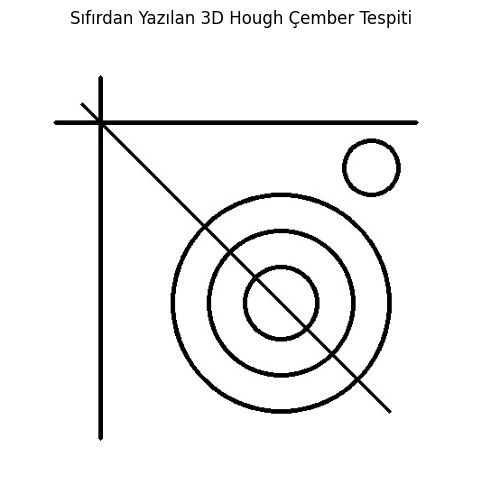

In [31]:
def custom_hough_circles(edge_image, r_min=30, r_max=130, r_step=5):
    height, width = edge_image.shape
    radii = np.arange(r_min, r_max, r_step)
    num_radii = len(radii)

    accumulator = np.zeros((height, width, num_radii), dtype=np.int32)
    angles = np.deg2rad(np.arange(0, 360, 5))
    cos_a = np.cos(angles)
    sin_a = np.sin(angles)

    y_idxs, x_idxs = np.nonzero(edge_image)

    for i in range(len(x_idxs)):
        x, y = x_idxs[i], y_idxs[i]
        for r_idx, r in enumerate(radii):
            for t_idx in range(len(angles)):
                a = int(np.round(x - r * cos_a[t_idx]))
                b = int(np.round(y - r * sin_a[t_idx]))
                if 0 <= a < width and 0 <= b < height:
                    accumulator[b, a, r_idx] += 1

    return accumulator, radii

# Performans kazanımı için kenar görselini boyutlandırıp arayalım
resized_edges = cv2.resize(edges_blurred, (256, 256))
accum_3d, radii = custom_hough_circles(resized_edges, r_min=15, r_max=70, r_step=4)

scale_y = edges_blurred.shape[0] / 256.0
scale_x = edges_blurred.shape[1] / 256.0

custom_circles_draw = img.copy()
# Yüksek oylu çember merkezlerini filtreleme
indices = np.argwhere(accum_3d > 45)

for b, a, r_idx in indices:
    real_x = int(a * scale_x)
    real_y = int(b * scale_y)
    real_r = int(radii[r_idx] * ((scale_x + scale_y) / 2.0))
    cv2.circle(custom_circles_draw, (real_x, real_y), real_r, (0, 165, 255), 2)

plt.figure(figsize=(6, 6))
plt.imshow(cv2.cvtColor(custom_circles_draw, cv2.COLOR_BGR2RGB))
plt.title('Sıfırdan Yazılan 3D Hough Çember Tespiti')
plt.axis('off')
plt.show()

## Task-5: Eş Merkezli Çember Tespiti (Custom Concentric Voting)

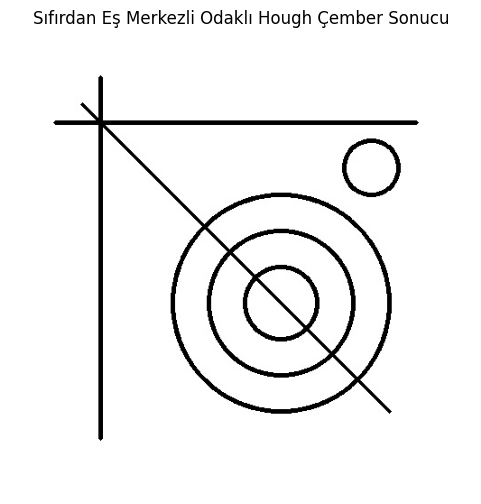

In [32]:
def custom_concentric_hough(edge_image, r_min=15, r_max=70, r_step=4):
    height, width = edge_image.shape
    radii = np.arange(r_min, r_max, r_step)
    num_radii = len(radii)

    accumulator = np.zeros((height, width, num_radii), dtype=np.int32)
    angles = np.deg2rad(np.arange(0, 360, 6))
    cos_a = np.cos(angles)
    sin_a = np.sin(angles)

    y_idxs, x_idxs = np.nonzero(edge_image)

    # Temel Oylama
    for i in range(len(x_idxs)):
        x, y = x_idxs[i], y_idxs[i]
        for r_idx, r in enumerate(radii):
            for t_idx in range(len(angles)):
                a = int(np.round(x - r * cos_a[t_idx]))
                b = int(np.round(y - r * sin_a[t_idx]))
                if 0 <= a < width and 0 <= b < height:
                    accumulator[b, a, r_idx] += 1

    # Eş merkezli oyları güçlendirme (Aynı merkezde birden fazla yarıçap eşleşmesi)
    concentric_accumulator = np.zeros_like(accumulator)
    for y in range(height):
        for x in range(width):
            votes = accumulator[y, x, :]
            active_radii = np.sum(votes > 25)
            if active_radii >= 2:
                concentric_accumulator[y, x, :] = votes * active_radii
            else:
                concentric_accumulator[y, x, :] = votes

    return concentric_accumulator, radii

conc_accum_3d, conc_radii = custom_concentric_hough(resized_edges, r_min=15, r_max=70, r_step=4)

concentric_draw = img.copy()
indices_conc = np.argwhere(conc_accum_3d > 75)

for b, a, r_idx in indices_conc:
    real_x = int(a * scale_x)
    real_y = int(b * scale_y)
    real_r = int(conc_radii[r_idx] * ((scale_x + scale_y) / 2.0))
    cv2.circle(concentric_draw, (real_x, real_y), real_r, (255, 255, 0), 2)

plt.figure(figsize=(6, 6))
plt.imshow(cv2.cvtColor(concentric_draw, cv2.COLOR_BGR2RGB))
plt.title('Sıfırdan Eş Merkezli Odaklı Hough Çember Sonucu')
plt.axis('off')
plt.show()

## Task-6: CUDA (GPU) Paralel Hough Line Tespiti

CUDA (CuPy) Paralel Hough Line Hesaplama Süresi: 0.115376 saniye.


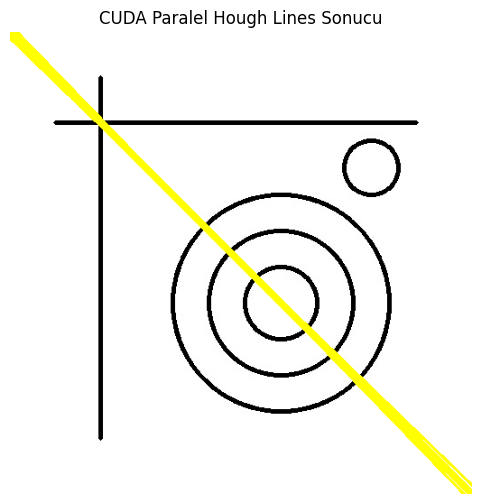

In [33]:
import cupy as cp
import time

def cuda_hough_lines(edge_image, theta_res=1, rho_res=1):
    height, width = edge_image.shape

    d_edge = cp.array(edge_image)
    thetas = cp.deg2rad(cp.arange(-90.0, 90.0, theta_res))
    diag_len = int(cp.ceil(cp.sqrt(height**2 + width**2)))
    rhos = cp.arange(-diag_len, diag_len, rho_res)

    num_thetas = len(thetas)
    num_rhos = len(rhos)

    y_idxs, x_idxs = cp.nonzero(d_edge)
    d_accumulator = cp.zeros((num_rhos, num_thetas), dtype=cp.int32)

    t_start = time.time()

    cos_t = cp.cos(thetas)
    sin_t = cp.sin(thetas)

    # Vektörize hesaplama
    rho_vals = x_idxs[:, None] * cos_t[None, :] + y_idxs[:, None] * sin_t[None, :]
    rho_indices = cp.round(rho_vals + diag_len).astype(cp.int32)

    for t_idx in range(num_thetas):
        col_indices = rho_indices[:, t_idx]
        valid_mask = (col_indices >= 0) & (col_indices < num_rhos)
        valid_rhos = col_indices[valid_mask]
        counts = cp.bincount(valid_rhos, minlength=num_rhos)
        d_accumulator[:, t_idx] = counts

    cp.cuda.Device(0).synchronize()
    cuda_time = time.time() - t_start

    return d_accumulator.get(), thetas.get(), rhos.get(), cuda_time

cuda_accum, cuda_thetas, cuda_rhos, cuda_duration = cuda_hough_lines(edges_blurred)
print(f"CUDA (CuPy) Paralel Hough Line Hesaplama Süresi: {cuda_duration:.6f} saniye.")

cuda_line_img = img.copy()
indices_cuda = np.argwhere(cuda_accum > 150)

for rho_idx, t_idx in indices_cuda:
    rho = cuda_rhos[rho_idx]
    theta = cuda_thetas[t_idx]
    a, b = np.cos(theta), np.sin(theta)
    x0, y0 = a * rho, b * rho
    x1 = int(x0 + 1000 * (-b))
    y1 = int(y0 + 1000 * (a))
    x2 = int(x0 - 1000 * (-b))
    y2 = int(y0 - 1000 * (a))
    cv2.line(cuda_line_img, (x1, y1), (x2, y2), (0, 255, 255), 2)

plt.figure(figsize=(6, 6))
plt.imshow(cv2.cvtColor(cuda_line_img, cv2.COLOR_BGR2RGB))
plt.title('CUDA Paralel Hough Lines Sonucu')
plt.axis('off')
plt.show()

```markdown
# Hough Dönüşümü ile Çizgi ve Çember Tespiti Ödevi (Yeni Başlangıç)

Bu çalışmada hem doğrusal hem de dairesel (özellikle eş merkezli) geometrik yapıları barındıran net bir sentetik görsel oluşturarak Hough Dönüşümü adımlarını sıfırdan ve kütüphaneler yardımıyla adım adım uygulayacağız.
```

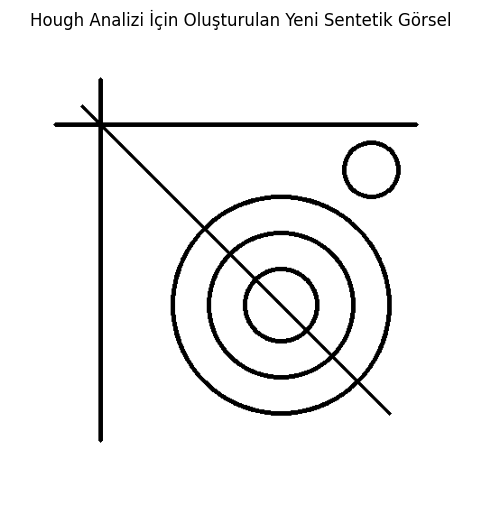

In [14]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Analiz için temiz ve net geometrik şekiller içeren sentetik bir görsel üretelim.
synthetic_img = np.ones((512, 512, 3), dtype=np.uint8) * 255

# Belirgin Düz Çizgiler Çizelim (Siyah)
cv2.line(synthetic_img, (50, 100), (450, 100), (0, 0, 0), 3) # Yatay Çizgi
cv2.line(synthetic_img, (100, 50), (100, 450), (0, 0, 0), 3) # Dikey Çizgi
cv2.line(synthetic_img, (80, 80), (420, 420), (0, 0, 0), 3)   # Çapraz Çizgi

# Belirgin Eş Merkezli Çemberler Çizelim (Merkez: 300, 300)
cv2.circle(synthetic_img, (300, 300), 40, (0, 0, 0), 3)
cv2.circle(synthetic_img, (300, 300), 80, (0, 0, 0), 3)
cv2.circle(synthetic_img, (300, 300), 120, (0, 0, 0), 3)

# Tekil bir çember daha çizelim (Merkez: 400, 150)
cv2.circle(synthetic_img, (400, 150), 30, (0, 0, 0), 3)

cv2.imwrite('clean_target.jpg', synthetic_img)

# Görseli gösterelim
plt.figure(figsize=(6, 6))
plt.imshow(cv2.cvtColor(synthetic_img, cv2.COLOR_BGR2RGB))
plt.title('Hough Analizi İçin Oluşturulan Yeni Sentetik Görsel')
plt.axis('off')
plt.show()

```markdown
## Task-1: Canny, Median Filtre ve OpenCV Hough Hatları
```

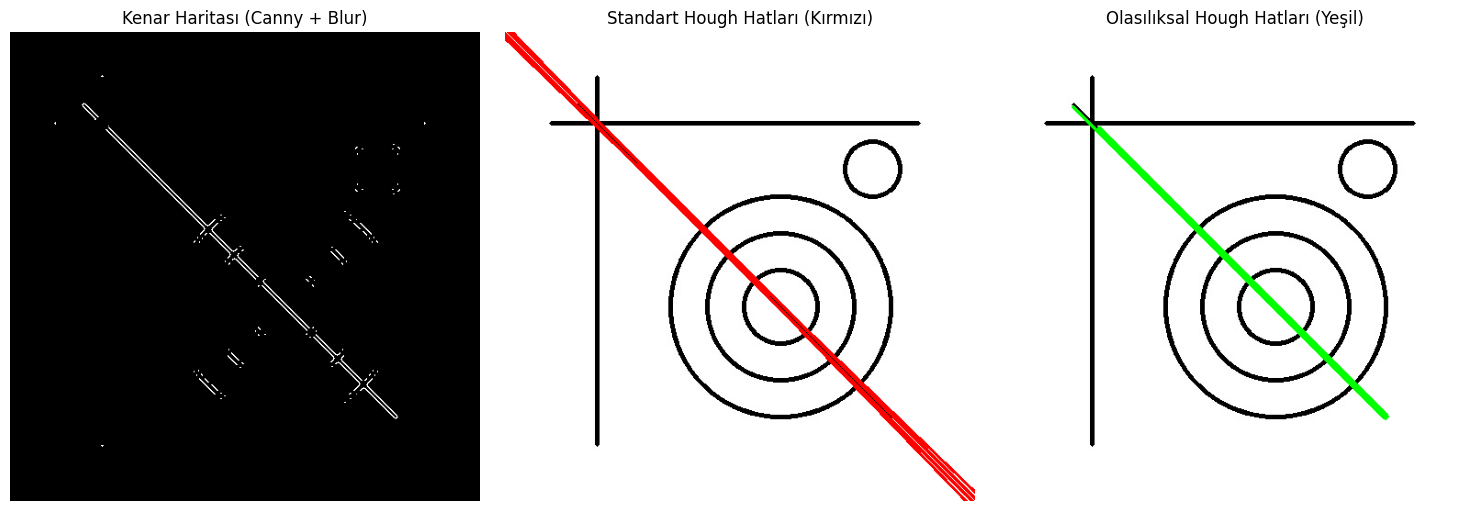

In [15]:
img = cv2.imread('clean_target.jpg')
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Kenar Tespiti ve Gürültü Filtreleme
edges = cv2.Canny(gray, 50, 150)
edges_blurred = cv2.medianBlur(edges, 3)

img_hough = img.copy()
img_hough_p = img.copy()

# 1. Standart Hough Çizgileri
lines = cv2.HoughLines(edges_blurred, 1, np.pi/180, 150)
if lines is not None:
    for r_t in lines:
        rho, theta = r_t[0]
        a = np.cos(theta)
        b = np.sin(theta)
        x0 = a * rho
        y0 = b * rho
        x1 = int(x0 + 1000 * (-b))
        y1 = int(y0 + 1000 * (a))
        x2 = int(x0 - 1000 * (-b))
        y2 = int(y0 - 1000 * (a))
        cv2.line(img_hough, (x1, y1), (x2, y2), (0, 0, 255), 2)

# 2. Olasılıksal Hough Çizgileri
lines_p = cv2.HoughLinesP(edges_blurred, 1, np.pi/180, 80, minLineLength=50, maxLineGap=10)
if lines_p is not None:
    for line in lines_p:
        x1, y1, x2, y2 = line[0]
        cv2.line(img_hough_p, (x1, y1), (x2, y2), (0, 255, 0), 2)

# Görselleştirme
plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.imshow(edges_blurred, cmap='gray')
plt.title('Kenar Haritası (Canny + Blur)')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(cv2.cvtColor(img_hough, cv2.COLOR_BGR2RGB))
plt.title('Standart Hough Hatları (Kırmızı)')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(cv2.cvtColor(img_hough_p, cv2.COLOR_BGR2RGB))
plt.title('Olasılıksal Hough Hatları (Yeşil)')
plt.axis('off')

plt.tight_layout()
plt.show()

```markdown
## Task-2: Sıfırdan (From Scratch) Hough Çizgi Tespiti
```

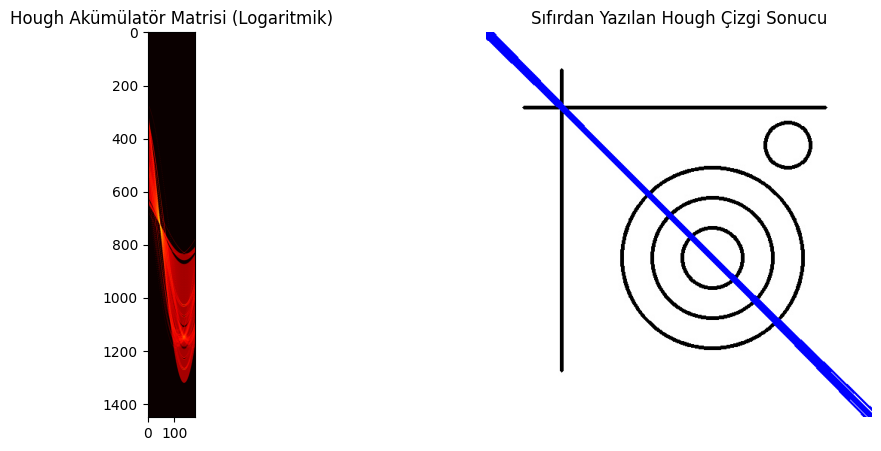

In [16]:
def custom_hough_lines(edge_image, theta_res=1, rho_res=1):
    height, width = edge_image.shape
    thetas = np.deg2rad(np.arange(-90.0, 90.0, theta_res))
    num_thetas = len(thetas)

    diag_len = int(np.ceil(np.sqrt(height**2 + width**2)))
    rhos = np.arange(-diag_len, diag_len, rho_res)
    num_rhos = len(rhos)

    cos_t = np.cos(thetas)
    sin_t = np.sin(thetas)

    accumulator = np.zeros((num_rhos, num_thetas), dtype=np.int32)
    y_idxs, x_idxs = np.nonzero(edge_image)

    for i in range(len(x_idxs)):
        x, y = x_idxs[i], y_idxs[i]
        for t_idx in range(num_thetas):
            rho_val = x * cos_t[t_idx] + y * sin_t[t_idx]
            rho_idx = int(np.round(rho_val + diag_len) / rho_res)
            if 0 <= rho_idx < num_rhos:
                accumulator[rho_idx, t_idx] += 1

    return accumulator, thetas, rhos

accum, thetas, rhos = custom_hough_lines(edges_blurred)

# Sonuçları Çizelim
custom_lines_img = img.copy()
indices = np.argwhere(accum > 150)
for r_idx, t_idx in indices:
    rho = rhos[r_idx]
    theta = thetas[t_idx]
    a, b = np.cos(theta), np.sin(theta)
    x0, y0 = a * rho, b * rho
    x1 = int(x0 + 1000 * (-b))
    y1 = int(y0 + 1000 * (a))
    x2 = int(x0 - 1000 * (-b))
    y2 = int(y0 - 1000 * (a))
    cv2.line(custom_lines_img, (x1, y1), (x2, y2), (255, 0, 0), 2)

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.imshow(np.log(accum + 1), cmap='hot')
plt.title('Hough Akümülatör Matrisi (Logaritmik)')

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(custom_lines_img, cv2.COLOR_BGR2RGB))
plt.title('Sıfırdan Yazılan Hough Çizgi Sonucu')
plt.axis('off')
plt.show()

```markdown
## Task-3: Canny, Median Filtre ve OpenCV Hough Çemberleri
```

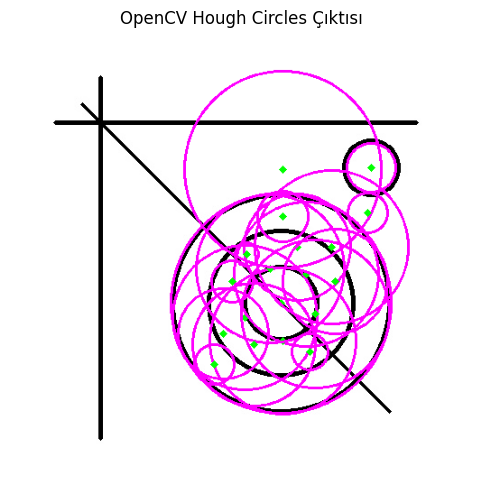

In [17]:
opencv_circles_img = img.copy()

# OpenCV HoughCircles Metodu
circles = cv2.HoughCircles(gray, cv2.HOUGH_GRADIENT, dp=1, minDist=30,
                           param1=100, param2=20, minRadius=10, maxRadius=150)

if circles is not None:
    circles = np.uint16(np.around(circles))
    for i in circles[0, :]:
        # Merkez
        cv2.circle(opencv_circles_img, (i[0], i[1]), 2, (0, 255, 0), 3)
        # Çember Çevresi
        cv2.circle(opencv_circles_img, (i[0], i[1]), i[2], (255, 0, 255), 2)

plt.figure(figsize=(6, 6))
plt.imshow(cv2.cvtColor(opencv_circles_img, cv2.COLOR_BGR2RGB))
plt.title('OpenCV Hough Circles Çıktısı')
plt.axis('off')
plt.show()

```markdown
## Task-4: Sıfırdan 3D Akümülatör ile Hough Çember Tespiti
```

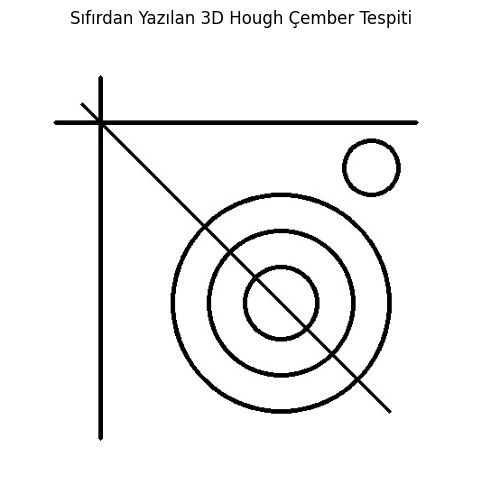

In [18]:
def custom_hough_circles(edge_image, r_min=30, r_max=130, r_step=5):
    height, width = edge_image.shape
    radii = np.arange(r_min, r_max, r_step)
    num_radii = len(radii)

    accumulator = np.zeros((height, width, num_radii), dtype=np.int32)
    angles = np.deg2rad(np.arange(0, 360, 5))
    cos_a = np.cos(angles)
    sin_a = np.sin(angles)

    y_idxs, x_idxs = np.nonzero(edge_image)

    for i in range(len(x_idxs)):
        x, y = x_idxs[i], y_idxs[i]
        for r_idx, r in enumerate(radii):
            for t_idx in range(len(angles)):
                a = int(np.round(x - r * cos_a[t_idx]))
                b = int(np.round(y - r * sin_a[t_idx]))
                if 0 <= a < width and 0 <= b < height:
                    accumulator[b, a, r_idx] += 1

    return accumulator, radii

# Performans kazanımı için kenar görselini boyutlandırıp arayalım
resized_edges = cv2.resize(edges_blurred, (256, 256))
accum_3d, radii = custom_hough_circles(resized_edges, r_min=15, r_max=70, r_step=4)

scale_y = edges_blurred.shape[0] / 256.0
scale_x = edges_blurred.shape[1] / 256.0

custom_circles_draw = img.copy()
# Yüksek oylu çember merkezlerini filtreleme
indices = np.argwhere(accum_3d > 45)

for b, a, r_idx in indices:
    real_x = int(a * scale_x)
    real_y = int(b * scale_y)
    real_r = int(radii[r_idx] * ((scale_x + scale_y) / 2.0))
    cv2.circle(custom_circles_draw, (real_x, real_y), real_r, (0, 165, 255), 2)

plt.figure(figsize=(6, 6))
plt.imshow(cv2.cvtColor(custom_circles_draw, cv2.COLOR_BGR2RGB))
plt.title('Sıfırdan Yazılan 3D Hough Çember Tespiti')
plt.axis('off')
plt.show()

```markdown
## Task-5: Eş Merkezli Çember Tespiti (Custom Concentric Voting)
```

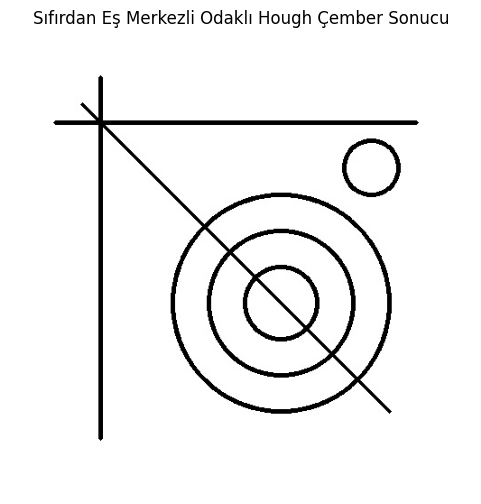

In [19]:
def custom_concentric_hough(edge_image, r_min=15, r_max=70, r_step=4):
    height, width = edge_image.shape
    radii = np.arange(r_min, r_max, r_step)
    num_radii = len(radii)

    accumulator = np.zeros((height, width, num_radii), dtype=np.int32)
    angles = np.deg2rad(np.arange(0, 360, 6))
    cos_a = np.cos(angles)
    sin_a = np.sin(angles)

    y_idxs, x_idxs = np.nonzero(edge_image)

    # Temel Oylama
    for i in range(len(x_idxs)):
        x, y = x_idxs[i], y_idxs[i]
        for r_idx, r in enumerate(radii):
            for t_idx in range(len(angles)):
                a = int(np.round(x - r * cos_a[t_idx]))
                b = int(np.round(y - r * sin_a[t_idx]))
                if 0 <= a < width and 0 <= b < height:
                    accumulator[b, a, r_idx] += 1

    # Eş merkezli oyları güçlendirme (Aynı merkezde birden fazla yarıçap eşleşmesi)
    concentric_accumulator = np.zeros_like(accumulator)
    for y in range(height):
        for x in range(width):
            votes = accumulator[y, x, :]
            active_radii = np.sum(votes > 25)
            if active_radii >= 2:
                concentric_accumulator[y, x, :] = votes * active_radii
            else:
                concentric_accumulator[y, x, :] = votes

    return concentric_accumulator, radii

conc_accum_3d, conc_radii = custom_concentric_hough(resized_edges, r_min=15, r_max=70, r_step=4)

concentric_draw = img.copy()
indices_conc = np.argwhere(conc_accum_3d > 75)

for b, a, r_idx in indices_conc:
    real_x = int(a * scale_x)
    real_y = int(b * scale_y)
    real_r = int(conc_radii[r_idx] * ((scale_x + scale_y) / 2.0))
    cv2.circle(concentric_draw, (real_x, real_y), real_r, (255, 255, 0), 2)

plt.figure(figsize=(6, 6))
plt.imshow(cv2.cvtColor(concentric_draw, cv2.COLOR_BGR2RGB))
plt.title('Sıfırdan Eş Merkezli Odaklı Hough Çember Sonucu')
plt.axis('off')
plt.show()

```markdown
## Task-6: CUDA (GPU) Paralel Hough Line Tespiti
```

CUDA (CuPy) Paralel Hough Line Hesaplama Süresi: 0.130250 saniye.


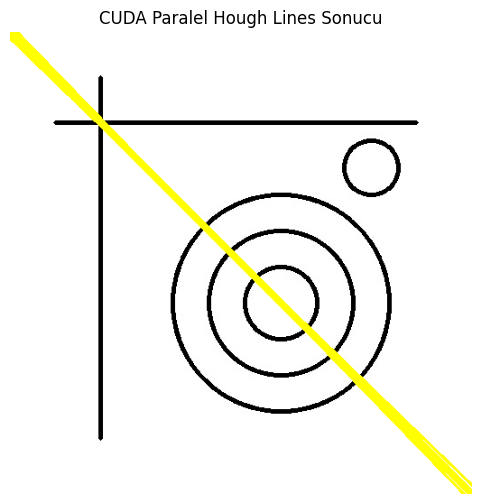

In [20]:
import cupy as cp
import time

def cuda_hough_lines(edge_image, theta_res=1, rho_res=1):
    height, width = edge_image.shape

    d_edge = cp.array(edge_image)
    thetas = cp.deg2rad(cp.arange(-90.0, 90.0, theta_res))
    diag_len = int(cp.ceil(cp.sqrt(height**2 + width**2)))
    rhos = cp.arange(-diag_len, diag_len, rho_res)

    num_thetas = len(thetas)
    num_rhos = len(rhos)

    y_idxs, x_idxs = cp.nonzero(d_edge)
    d_accumulator = cp.zeros((num_rhos, num_thetas), dtype=cp.int32)

    t_start = time.time()

    cos_t = cp.cos(thetas)
    sin_t = cp.sin(thetas)

    # Vektörize hesaplama
    rho_vals = x_idxs[:, None] * cos_t[None, :] + y_idxs[:, None] * sin_t[None, :]
    rho_indices = cp.round(rho_vals + diag_len).astype(cp.int32)

    for t_idx in range(num_thetas):
        col_indices = rho_indices[:, t_idx]
        valid_mask = (col_indices >= 0) & (col_indices < num_rhos)
        valid_rhos = col_indices[valid_mask]
        counts = cp.bincount(valid_rhos, minlength=num_rhos)
        d_accumulator[:, t_idx] = counts

    cp.cuda.Device(0).synchronize()
    cuda_time = time.time() - t_start

    return d_accumulator.get(), thetas.get(), rhos.get(), cuda_time

cuda_accum, cuda_thetas, cuda_rhos, cuda_duration = cuda_hough_lines(edges_blurred)
print(f"CUDA (CuPy) Paralel Hough Line Hesaplama Süresi: {cuda_duration:.6f} saniye.")

cuda_line_img = img.copy()
indices_cuda = np.argwhere(cuda_accum > 150)

for rho_idx, t_idx in indices_cuda:
    rho = cuda_rhos[rho_idx]
    theta = cuda_thetas[t_idx]
    a, b = np.cos(theta), np.sin(theta)
    x0, y0 = a * rho, b * rho
    x1 = int(x0 + 1000 * (-b))
    y1 = int(y0 + 1000 * (a))
    x2 = int(x0 - 1000 * (-b))
    y2 = int(y0 - 1000 * (a))
    cv2.line(cuda_line_img, (x1, y1), (x2, y2), (0, 255, 255), 2)

plt.figure(figsize=(6, 6))
plt.imshow(cv2.cvtColor(cuda_line_img, cv2.COLOR_BGR2RGB))
plt.title('CUDA Paralel Hough Lines Sonucu')
plt.axis('off')
plt.show()